# Does a half-known word map carry to keys it never saw, at 24 and at 96 trained keys, and does VPD agree?

*E58 and its Amendments 1 to 7, 2026-10-30. Record and full tables: `reports/analyses/2026-10-30_analysis_e58-open-pair.md`.
Plan: `reports/plans/2026-10-30_plan_e58-open-pair.md`. Words as in `GOALS.md` → Terms.*

## The answer

The decomposition's main reading follows whether the trained answer is the model's own guess, not whether learning
carries to unseen keys. A new four-word rule, built on directions the model already has, carried most of the way to
unseen keys yet read as new, like a lookup over the same words. Copy, which carries as far, reads high. A lookup at
nearly copy's prior reads low, so the reading is not a smooth trend in the prior. All of this is one small model and
one decomposition, and provisional.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "open_pair"
RUN = json.loads((EXP / "results" / "run.json").read_text())
ST, SC = RUN["states"], RUN["score"]
A1 = json.loads((EXP / "results" / "amend1.json").read_text())
A2 = json.loads((EXP / "results" / "amend2.json").read_text())
A3 = json.loads((EXP / "results" / "amend3.json").read_text())
A4 = json.loads((EXP / "results" / "amend4.json").read_text())
A6 = json.loads((EXP / "results" / "amend6.json").read_text())
# figures: experiments/open_pair/plot.py (E58, Amendment 1), plot_amend3.py, plot_amend4.py and plot_amend6.py
# (Amendments 3, 4, 6), from the JSON only
print("stage-0 controls passed:", RUN["stage0"]["pass"], "| elicit labels:", SC["P0"]["labels"],
      "| cipher labels:", SC["P1"]["labels"])
print("Amendment 1 verdict:", A1["score"]["verdict"], "| copy labels:", A1["score"]["C2"]["labels"],
      "| rank-1 labels:", A1["score"]["C1"]["labels"])
print("Amendment 2:", A2["stopped"], "| elicit x", round(A2["states"]["elicit"]["x"], 3))
print("Amendment 3: control", A3["score"]["control"], "| R", A3["score"]["R"], "| C", A3["score"]["C"],
      "| B", A3["score"]["B"]["status"], "| verdict", A3["score"]["verdict"])
W4 = A4["score"]["within_key"]
print("Amendment 4: controls", {s: c["status"] for s, c in A4["control"].items()}, "| within-key rule", W4["10"]["status"],
      W4["30"]["status"], "| shuffle", A4["score"]["shuffle"])
print("Amendment 6: W0 control", A6["w0_control"]["pass"], "| harness control", A6["harness_control"]["pass"],
      "| PM", A6["score"]["PM"]["class"], "| FL", A6["score"]["FL"]["class"])

stage-0 controls passed: True | elicit labels: ['new', 'new', 'new'] | cipher labels: ['new', 'new', 'new']
Amendment 1 verdict: none | copy labels: ['neither', 'reuses', 'neither'] | rank-1 labels: ['neither', 'neither', 'neither']
Amendment 2: the control reads fail | elicit x 0.213
Amendment 3: control below | R between | C pass | B untested_drift | verdict untested
Amendment 4: controls {'0': 'below', '1': 'below', '2': 'below'} | within-key rule fail fail | shuffle cipher_like
Amendment 6: W0 control True | harness control True | PM cipher_band | FL no_carry


## What we were trying to test

The re-gating line asks whether a VPD decomposition can tell a fine-tune that strengthens something the model already
does from one that teaches something new. Its numbers have only been scored against labels fixed by how each task was
built. Here the label comes from behaviour alone.

**The task.** Each window is Pile text, then a rare marker token, then a key word; the model must predict the key's
value next. Two maps share the 32 keys and the windows. In the *elicit map*, each value is a word the original model W₀
already ranks 2nd to 20th after that key, such as " formed" → " from". In the *cipher*, the values are arbitrary words
W₀ almost never gives there. The cipher's unseen values cannot be guessed from its trained ones, so it is the label's
negative control.

**What changed.** E54's fine-tune recipe ran on only 24 of the 32 keys, three seeds per map. The other 8 keys never sat
at a training window's key position. The elicit map is read at step 10, when the trained keys are learned. The cipher is
read at the step whose total weight change matches the elicit state's.

**The label.** For a window, the *specific gain* is the fine-tune's rise in the log-odds of the window's own value, minus
the mean rise of the map's other 31 values. Subtracting them removes a shift shared by the whole value set. A first,
stopped job found such a shift on E54's cipher. The trained-key gain $G_\text{spec}$ is the mean specific gain on
unused windows of the trained keys. The held-out gain $H_\text{spec}$ is the same on the 8 held-out keys, and
$x = H_\text{spec} / G_\text{spec}$. At 0 the unseen keys gained
nothing; at 1 they gained as much as the trained ones. The label is "reuses" if $x \ge 0.5$ and "new" if $x$ is at or below
three bootstrap standard deviations $s$.

**The readings**, E54's, on the least-squares split of each weight change:

- $r$, the share of the fine-tune's gain recovered when the subcomponents stay at W₀'s and only Γ's CI values change. It
  reads 1 if switching existing subcomponents on carries all the gain.
- The *stand-in ratio*, the CI-masked model's gain over the gain of the split subcomponents with every mask open. It is
  roughly the gain from Γ's new CI values over the subcomponent gain, not "the share Γ keeps", and has no ceiling at 1.
- $S$, steering's share: one mean vector added at one block. It never reads the decomposition.

Each reading says "reuses" at 0.5 or more.

## What we expected, and why

We left the elicit label open, at about even odds for "reuses": if the fine-tune sharpened what W₀ already prefers after
each key, unseen keys would gain too. Every cipher had to read "new". We expected r and the stand-in ratio to stay high
on the elicit map, as in E54, so the prediction that they agree with the label would pass exactly when the label read
"reuses". We also expected both readings to separate the elicit map from the cipher again.

## Did the fine-tune carry over to the keys it never saw?

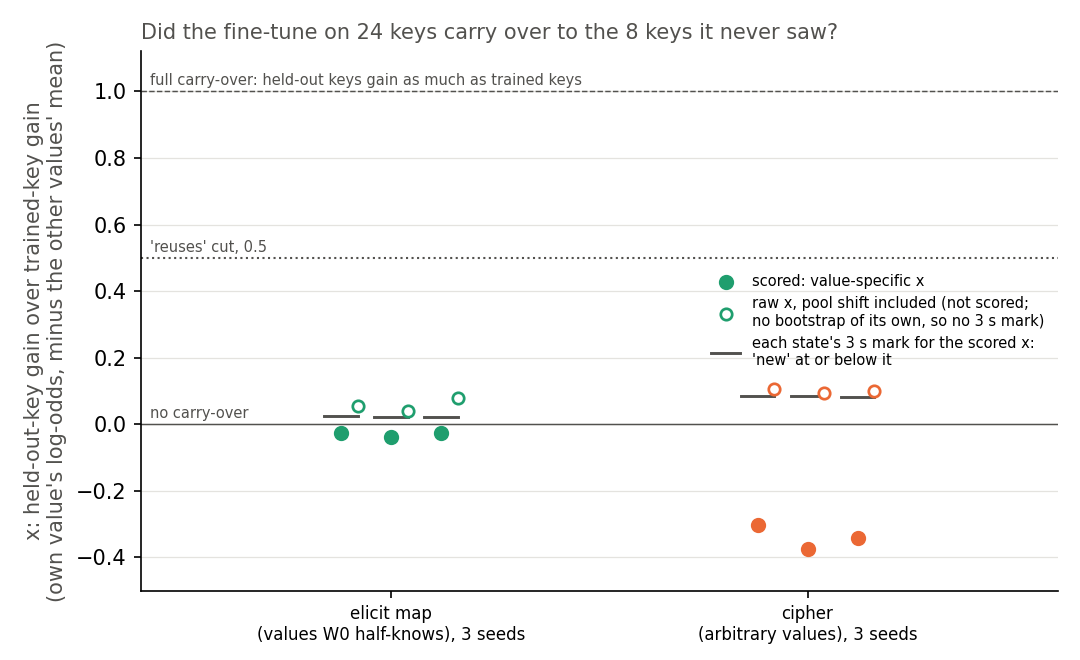

In [2]:
display(Image(filename=str(EXP / "figures" / "label.png")))

In [3]:
rows = ["| state | trained-key gain | held-out gain | x | label |", "|---|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['G_spec']:.2f} | {d['H_spec']:.2f} | {d['x']:.3f} | {d['label']} |")
display(Markdown("\n".join(rows)))

| state | trained-key gain | held-out gain | x | label |
|---|---|---|---|---|
| elicit, seed 0 | 18.18 | -0.50 | -0.027 | new |
| elicit, seed 1 | 18.43 | -0.70 | -0.038 | new |
| elicit, seed 2 | 18.51 | -0.48 | -0.026 | new |
| cipher, seed 0 | 10.67 | -3.24 | -0.303 | new |
| cipher, seed 1 | 9.39 | -3.54 | -0.377 | new |
| cipher, seed 2 | 9.94 | -3.40 | -0.342 | new |

**Reading it.** No. On all three elicit seeds the held-out keys' specific gain was slightly negative, so $x$ sits just
below 0 and the label is "new". The trained keys gained about 18 log-odds on the same measure. The cipher reads "new"
too, further below 0, so the negative control passed. The hollow points keep the shared shift in and read 0.04 to 0.08
for the elicit map, far from the cut; they have no bootstrap of their own, so no label. Resampling the 8 keys instead of windows changes no label.

## Was carry-over possible, or did the task rule it out?

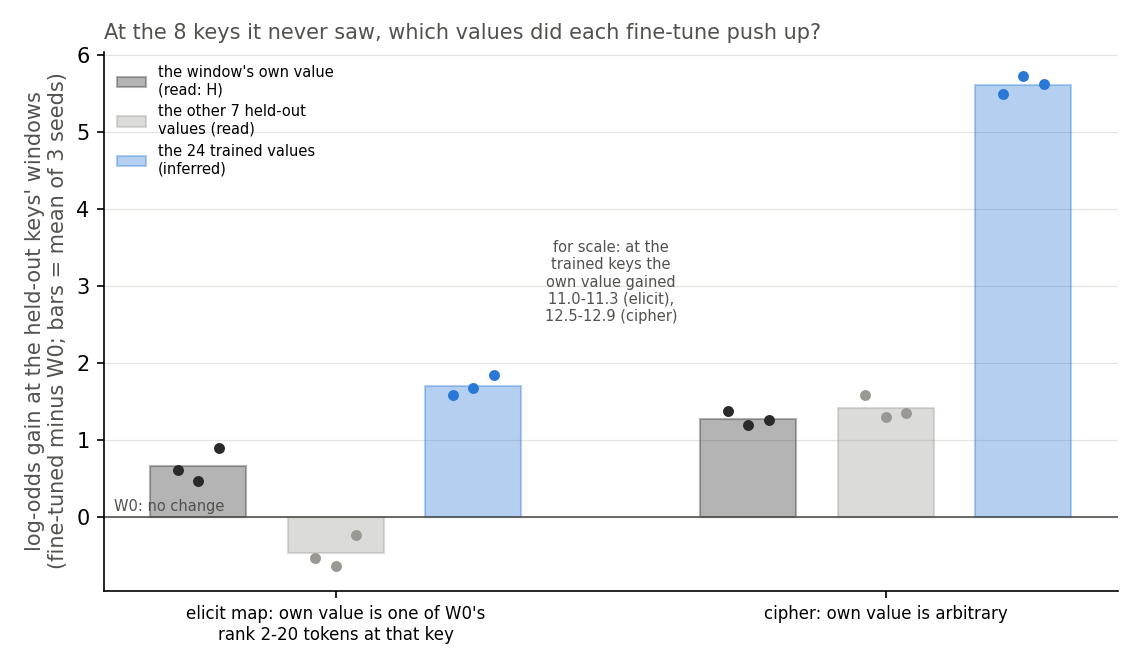

In [4]:
display(Image(filename=str(EXP / "figures" / "heldout_gain.png")))

**Reading it.** Carry-over was possible, and the fine-tune took that route only weakly. There is no rule from key to
value here, so the one way unseen keys could gain is a general sharpening of what W₀ already prefers after each key.
That would raise the held-out key's own value most. The own value rose by about 0.6 log-odds, while the 24 trained values
rose by about 1.7. Here the trained values' rise is inferred from three read means, since the 32 values
are distinct; Amendment 1 later read it directly and it agrees to within 5e-8 on all six states.

That push hides a small key-specific boost. Against its 7 held-out siblings, the own value gained about 1.1 more on the
elicit map, and about 0.1 to 0.2 less on the cipher. Each contrast comes from two read means. The boost is about 6% of the
trained keys' specific gain. So the update is mostly 24 lookups plus a push toward the trained values, with a small
key-specific boost. Amendment 1, below, reads the trained values' push directly; the label stands as filed.

In [5]:
rows = ["| state | own value | 7 held-out siblings | own minus siblings |", "|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['H']:+.2f} | {d['H_other']:+.2f} | {d['H'] - d['H_other']:+.3f} |")
display(Markdown("\n".join(rows)))

| state | own value | 7 held-out siblings | own minus siblings |
|---|---|---|---|
| elicit, seed 0 | +0.61 | -0.53 | +1.145 |
| elicit, seed 1 | +0.46 | -0.64 | +1.098 |
| elicit, seed 2 | +0.90 | -0.23 | +1.127 |
| cipher, seed 0 | +1.38 | +1.58 | -0.208 |
| cipher, seed 1 | +1.19 | +1.29 | -0.105 |
| cipher, seed 2 | +1.26 | +1.35 | -0.095 |

*Gains at the held-out keys' windows, log-odds, fine-tuned minus W₀.*

## Do the decomposition's readings agree with the label?

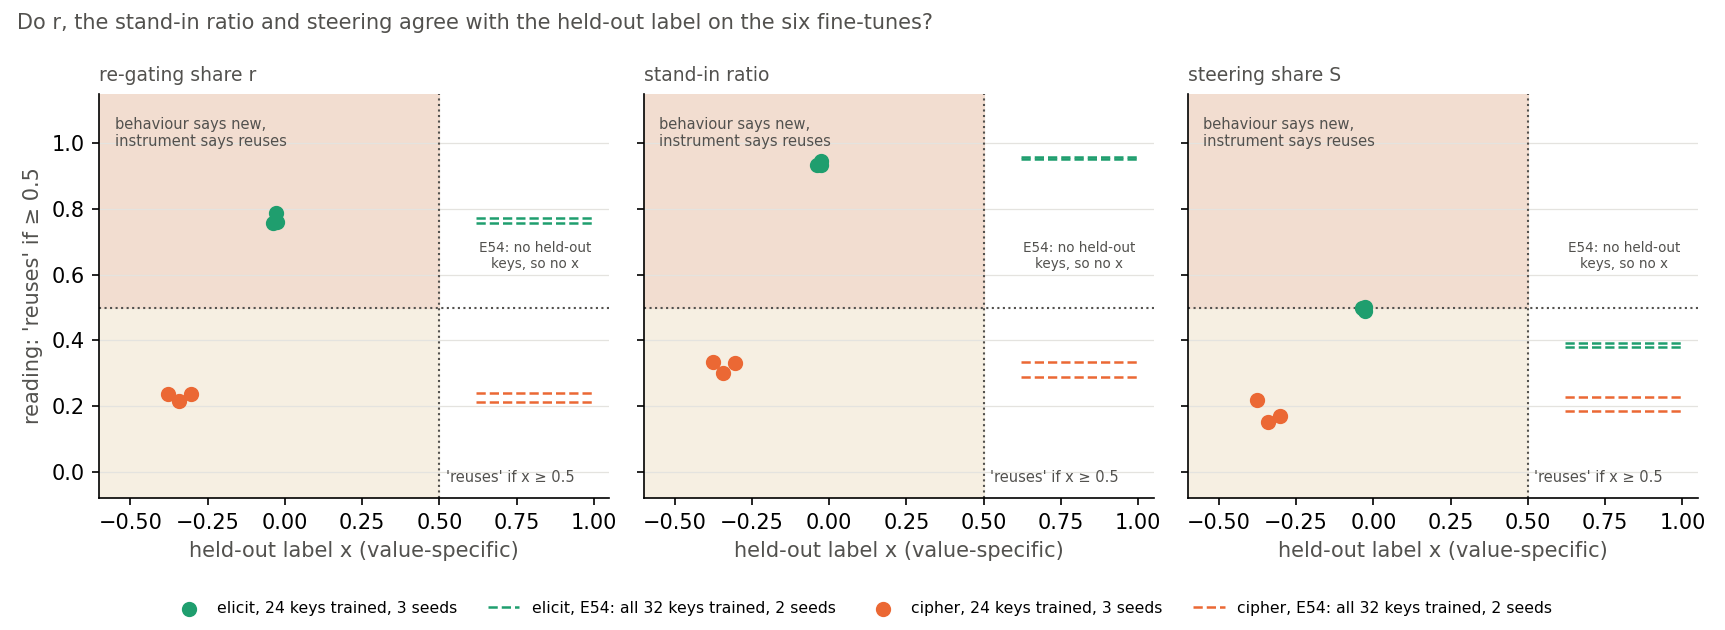

In [6]:
display(Image(filename=str(EXP / "figures" / "agreement.png")))

In [7]:
rows = ["| state | r | stand-in ratio | steering S | label |", "|---|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['r']:.3f} | {d['ratio']:.3f} | {d['S']:.3f} | {d['label']} |")
display(Markdown("\n".join(rows)))

| state | r | stand-in ratio | steering S | label |
|---|---|---|---|---|
| elicit, seed 0 | 0.787 | 0.946 | 0.501 | new |
| elicit, seed 1 | 0.757 | 0.934 | 0.498 | new |
| elicit, seed 2 | 0.758 | 0.934 | 0.490 | new |
| cipher, seed 0 | 0.236 | 0.330 | 0.171 | new |
| cipher, seed 1 | 0.238 | 0.336 | 0.220 | new |
| cipher, seed 2 | 0.217 | 0.302 | 0.152 | new |

**Reading it.** No: r and the stand-in ratio read "reuses" on every elicit state, while the label reads "new". The
green points sit in the upper-left box of the first two panels, level with E54's values for the same map with all keys
trained. Both readings still separate the elicit map from the cipher: r by 0.54 and the ratio by 0.62. Seed ranges are near 0.03.

Steering agrees with the label on more states, but that is not a finding. Its three elicit values are 0.50, 0.50 and
0.49, on its own cut, so it scores by sitting on the line. We keep it out of the headline.

## Amendment 1: two checks on how to read this

E58 left two doubts. Was "new" guaranteed by the task, or did the update really ignore what W₀ already prefers at unseen
keys? And can the label read "reuses" at all, when no state on this model ever had? A second job checked both at no cost.

**The readout.** On E58's six saved states, at the held-out keys' windows, we read three log-odds gains. They are the
gain of the window's own value, the gain $T$ of the trained keys' values, and the gain $R_\text{peer}$ of the other
words among W₀'s top 20 at that key. A lookup
pushes $T$ above $R_\text{peer}$. A sharpening of W₀ pushes $R_\text{peer}$ above 0. All three read 0 at W₀.

**The positive control.** Two new maps on the same windows, keys and 24/8 split, E54's recipe, three seeds. In the
*rank-1 map* each key's value is W₀'s own top next word after it, so "say what you would have said" holds at every key.
In the *copy map* each key's value is the key itself, one rule for every key. Both should carry to unseen keys and read
"reuses" under E58's unchanged label.

**What we expected.** A lookup on all three elicit states, at about 85%. The copy map reading "reuses" on two of three
seeds, at about 75%. The rank-1 map testable at about even odds, since it needs 3 held-out keys whose value no trained
key shares.

### At the unseen keys, did the update push the trained answers or W₀'s own preferences?

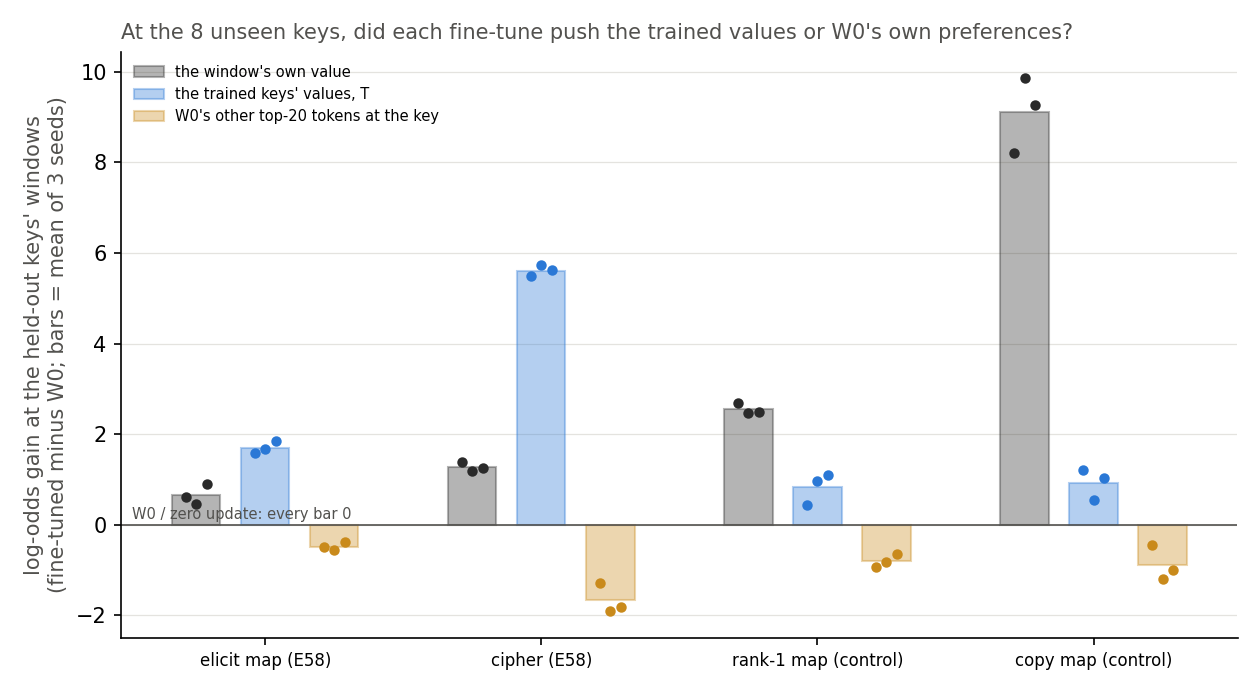

In [8]:
display(Image(filename=str(EXP / "figures" / "a1_readout.png")))

**Reading it.** The trained answers: on every elicit seed the update is a lookup, as filed. The 24 trained values rose
by 1.6 to 1.8 log-odds at unseen keys, while W₀'s other top-20 words there fell by 0.4 to 0.6. W₀'s first choice fell
too, so no sharpening hides at rank 1. The cipher reads the same, more strongly. One caveat: this verdict leaves the
own value out, so the copy map also reads "lookup", although its own value rose by 8 to 10 at unseen keys. It says what
else the update pushed, not whether it carried.

### Can the label read "reuses", and do the readings follow the carry?

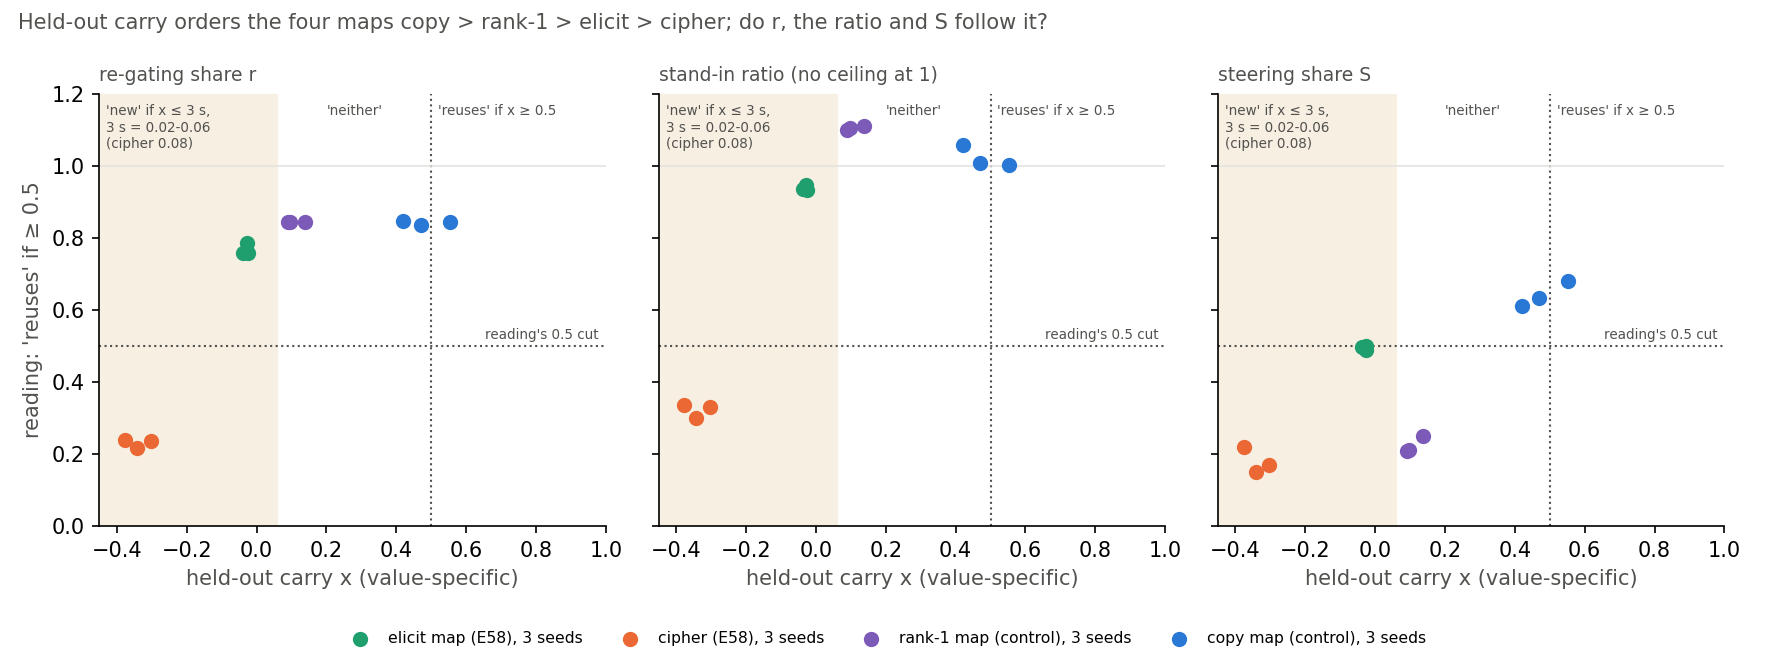

In [9]:
display(Image(filename=str(EXP / "figures" / "a1_carry.png")))

In [10]:
C = A1["control"]
rows = ["| state | held-out carry x | label | r | stand-in ratio |", "|---|---|---|---|---|"]
for m in ("rank1", "copy"):
    for s in (0, 1, 2):
        d = C[f"{m}_s{s}"]
        rows.append(f"| {m}, seed {s} | {d['x']:.3f} | {d['label']} | {d['r']:.3f} | {d['ratio']:.3f} |")
display(Markdown("\n".join(rows)))

| state | held-out carry x | label | r | stand-in ratio |
|---|---|---|---|---|
| rank1, seed 0 | 0.138 | neither | 0.845 | 1.110 |
| rank1, seed 1 | 0.097 | neither | 0.843 | 1.105 |
| rank1, seed 2 | 0.090 | neither | 0.843 | 1.099 |
| copy, seed 0 | 0.420 | neither | 0.846 | 1.057 |
| copy, seed 1 | 0.553 | reuses | 0.843 | 1.003 |
| copy, seed 2 | 0.470 | neither | 0.834 | 1.007 |

**Reading it.** Not at the filed bar: the positive control failed. Read the horizontal axis first. The copy map carried
most, 0.42 to 0.55 of the trained gain, and reads "reuses" on one seed of three. We predicted two of three at about 75%,
so that prediction fails. The rank-1 map carried 0.09 to 0.14 and could not be scored. Only one of its held-out keys has
a value of its own, so its carry can ride on the push toward trained values. In raw log-odds the copy map's unseen keys
gained 0.63 to 0.75 of the trained keys' gain. The value-specific measure is lower because, at trained keys only, the
map's other values fell by over 4 log-odds, which enlarges the denominator.

Now the vertical axes. The re-gating share r stays level across copy, rank-1 and elicit, at 0.76 to 0.85, while carry
runs from half to none. The stand-in ratio is flat the same way, and both separate only the cipher. Steering puts the
rank-1 map beside the cipher. The stand-in ratio exceeds 1 on both controls, and that is allowed: it is not a share. It
is close to the gain from Γ's new CI values alone over the gain of the split subcomponents with every mask open. Nothing
caps the first by the second.

## Amendments 2 and 3: four times the keys

At 24 trained keys every fine-tune mostly memorised its keys, and r stayed level whether carry was none or half. That
might only mean 24 keys are too few for a rule to beat a lookup. So the same maps were trained on 128 keys drawn by
E54's own rule, 96 trained and 32 held out, one seed, E54's recipe. Every map is read at one common step, the elicit
map's step 10, so that training length does not differ between maps. The question is whether a rule now carries, and
if so whether r and the stand-in ratio move with it. Under reading A, the lead's working answer that "reuses" means
"built from subcomponents W₀ already has", they should not.

**Amendment 2 stopped at its control.** The elicit map ran first, filed as a map with no rule, so its carry had to stay
within ±0.05 of 0; we gave it about 70%. It carried 0.21 of its trained-key gain, on 28 of 32 unseen keys, and the job
stopped as designed. That miss stands as filed. Fable's reasoned cause: each elicit value is a word W₀ already favours
after that key, so "say what W₀ half-expects here" is a rule, and 96 keys may make it learnable.

**Amendment 3** made the cipher, whose values no rule links, the control, and scored the elicit map. Each map is
compared with itself between 24 and 96 keys: the change in carry $dx$, and the changes $d_r$ and $d_\text{ratio}$ in r
and the stand-in ratio. A map is testable when $dx \ge 0.15$; it is "flat" if r moved by at most 0.05 and the ratio by at
most 0.1. Because no map is a reference for another, a guard reads the cipher's r at the step whose update size matches
the elicit state's. If it moved more than 0.05 from its 24-key value, the test reads "untested". Fable's checks ran
beside: the elicit carry at later steps, a shuffled elicit map, and whether per-key gains follow W₀'s preferences.

**What we expected.** The cipher reading below 0, about 75%. r and the ratio flat on every map, about 50%, and the
drift guard firing about 10%. The copy map reaching carry 0.6, about 40%.

### With 96 trained keys, does the half-known map carry, and does the carry last?

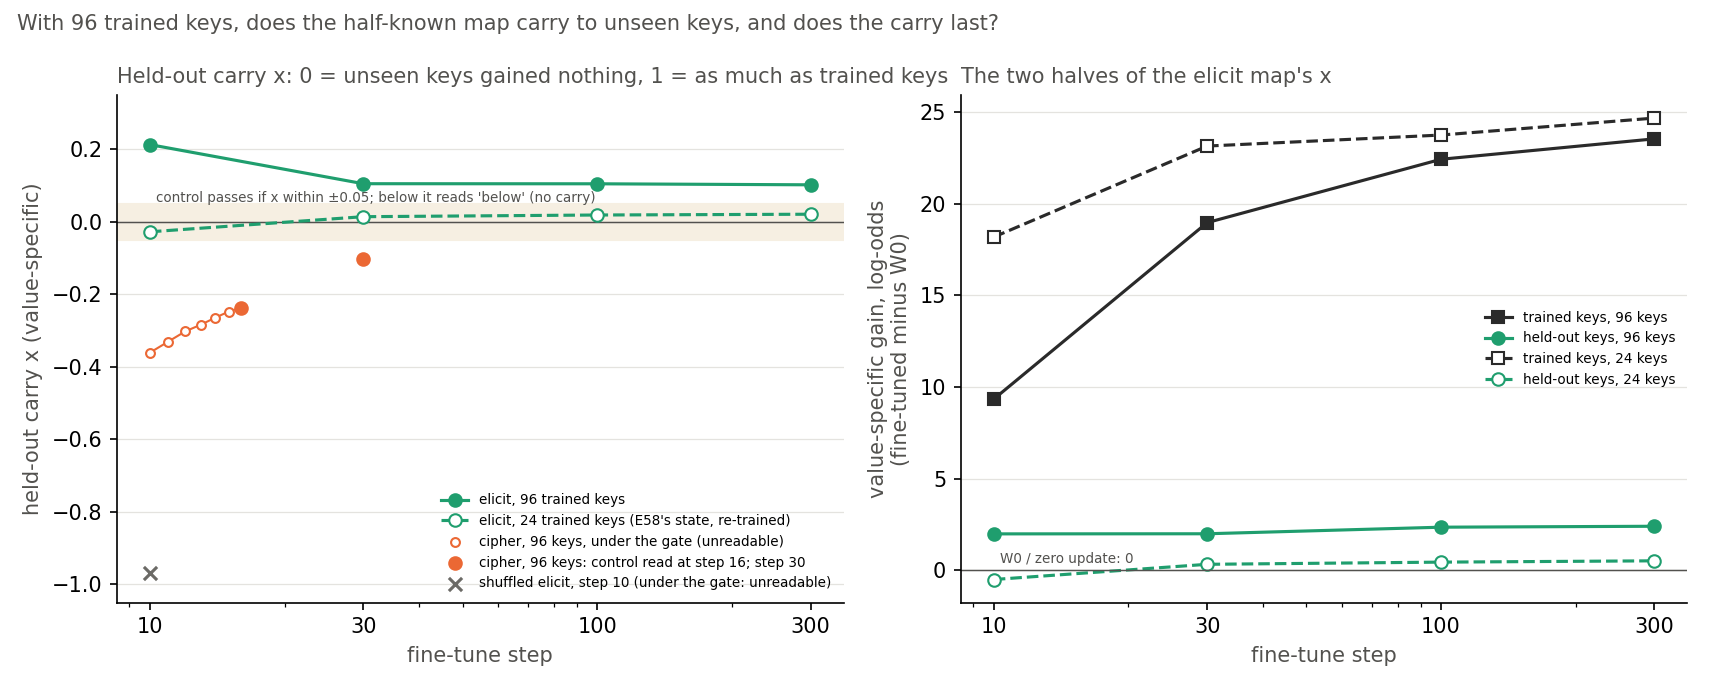

In [11]:
display(Image(filename=str(EXP / "figures" / "a3_carry.png")))

In [12]:
R3 = A3["reads"]
rows = ["| step | trained-key gain | held-out gain | x, 96 keys | x, 24 keys |", "|---|---|---|---|---|"]
for s in (10, 30, 100, 300):
    d, d24 = R3[f"elicit@{s}"], R3[f"elicit24@{s}"]
    rows.append(f"| {s} | {d['G_spec']:.2f} | {d['H_spec']:+.2f} | {d['x']:.3f} | {d24['x']:+.3f} |")
display(Markdown("\n".join(rows)))

| step | trained-key gain | held-out gain | x, 96 keys | x, 24 keys |
|---|---|---|---|---|
| 10 | 9.34 | +1.99 | 0.213 | -0.027 |
| 30 | 18.96 | +2.00 | 0.105 | +0.014 |
| 100 | 22.42 | +2.36 | 0.105 | +0.019 |
| 300 | 23.53 | +2.41 | 0.102 | +0.021 |

**Reading it.** Yes, about a fifth of the way at step 10 and a tenth from step 30 on, where at 24 keys it carried
nothing. In the left panel the solid green line reads 0.21 at step 10 and about 0.10 after. The dashed line, E58's
24-key state re-trained in this job, sits inside the control's band at every step. The cipher stays below 0 throughout;
read first, at step 16 where its trained-key gain clears the gate, it reads −0.24, "below", so the control passed. The
right panel shows why the carry halved. The unseen keys' gain held at about 2 log-odds, while the trained keys' gain
doubled by step 30.

Whether the carry is tied to each key's own value, the checks do not settle. The shuffled map's trained-key gain fell
under the gate, so its filed reading is "too small" and cannot be used. At 32 keys, the rank correlation of each key's
gain with W₀'s preference for its value was 0.01 and 0.19, too weak to tell from chance. One seed only.

### From 24 to 96 trained keys, did r and the stand-in ratio move with carry?

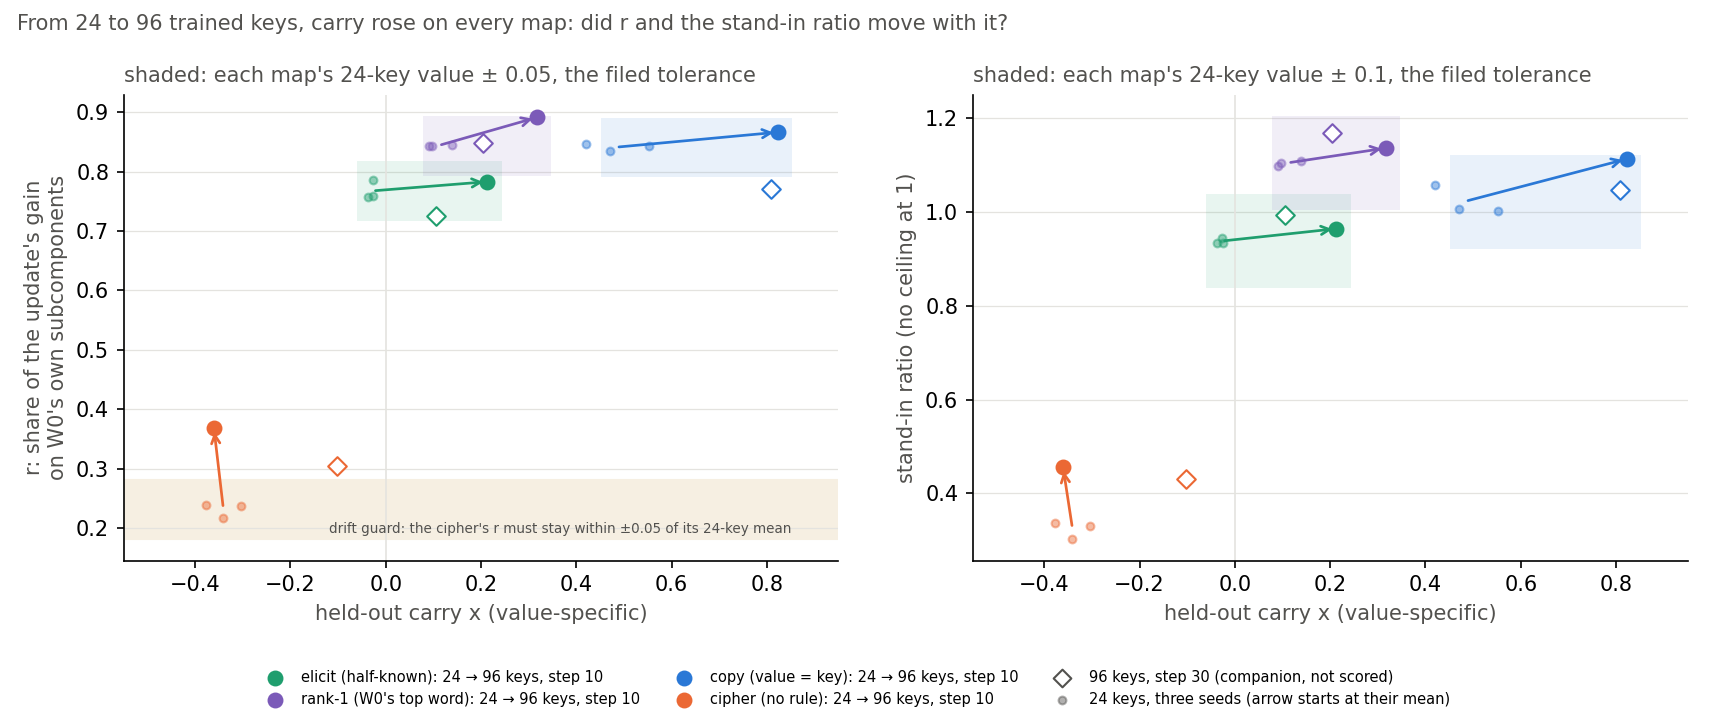

In [13]:
display(Image(filename=str(EXP / "figures" / "a3_shift.png")))

In [14]:
B = A3["score"]["B"]["maps"]
rows = ["| map, step 10 | x, 96 keys | carry rise | r change | ratio change |", "|---|---|---|---|---|"]
for m in ("elicit", "rank1", "copy"):
    rows.append(f"| {m} | {R3[m + '@10']['x']:.3f} | {B[m]['dx']:+.3f} | {B[m]['r']['d']:+.3f} | {B[m]['ratio']['d']:+.3f} |")
c = R3[f"cipher@{A3['cipher_matched_step']}"]
rows.append(f"| cipher, update size matched | {c['x']:.3f}, under the gate | — | {A3['score']['B']['cipher_r_drift']:+.3f} | — |")
display(Markdown("\n".join(rows)))

| map, step 10 | x, 96 keys | carry rise | r change | ratio change |
|---|---|---|---|---|
| elicit | 0.213 | +0.243 | +0.016 | +0.027 |
| rank1 | 0.317 | +0.208 | +0.048 | +0.032 |
| copy | 0.823 | +0.342 | +0.025 | +0.091 |
| cipher, update size matched | -0.361, under the gate | — | +0.138 | — |

**Reading it.** On no map did r or the ratio move beyond its tolerance, but the filed test reads "untested", because
the cipher's r moved too. Each arrow runs from a map's 24-key mean to its 96-key state. Carry rose by 0.21 to 0.34 on
the three maps, and every arrow head stays inside its shaded band. The cipher's arrow leaves its band: its r rose from
0.23 to 0.37, against a guard of 0.05. The filed rule then reads "untested", not "reading A holds". Two flat calls sit
just inside tolerance: rank-1's r moved 0.048, copy's ratio 0.091. The matched cipher at 96 keys had also barely learned
its values, unlike E58's ciphers, and we do not know why its r rose.

On the horizontal axis, the copy map now carries 0.82 and reads "reuses", so its filed prediction passes and the
held-out label has a positive control, on one seed. Across the three maps r sits at 0.78 to 0.89 while carry spans 0.21
to 0.82. That level picture fits reading A, as Amendment 1 did. It is subject to the granularity limit: r reads whether a
gain runs through subcomponents W₀ already has, and a new circuit built from them reads the same way.

## Amendment 4: three seeds for the level picture, and what the shuffled map's r reads

At 96 trained keys, on one seed, the three maps read nearly the same r while their carry ran from a fifth to four
fifths. Amendment 4 trains two more seeds of every map and of the cipher, reads each map at steps 10 and 30, and scores
a rule filed before the run. Per map it takes the seed means of carry and of r; the maps' r may differ by at most twice
the largest within-map seed range of r, when their carry differs by at least 0.4. The ratio's bound is 0.2. This is an
equivalence test with a wide margin, about 4.5 standard deviations of one map's seed spread.

The shuffled elicit map is also read over the gate. It has elicit's words, but each trained key takes another trained
key's value, so no value is what W₀ already expects after its key. If r reads the model's own guess per key, it should
fall toward the cipher; if it reads only the kind of word, it should stay near elicit. The filed cut is r 0.5 at step 30.

**What we expected.** Fable gave the rule a pass at about 70%, the plan's writer about 30%; both leans are filed. The
shuffle reading cipher-like, about 60%. Every seed's cipher, read first, reading "below".

### Across three seeds, does r differ between the three maps by no more than seed noise?

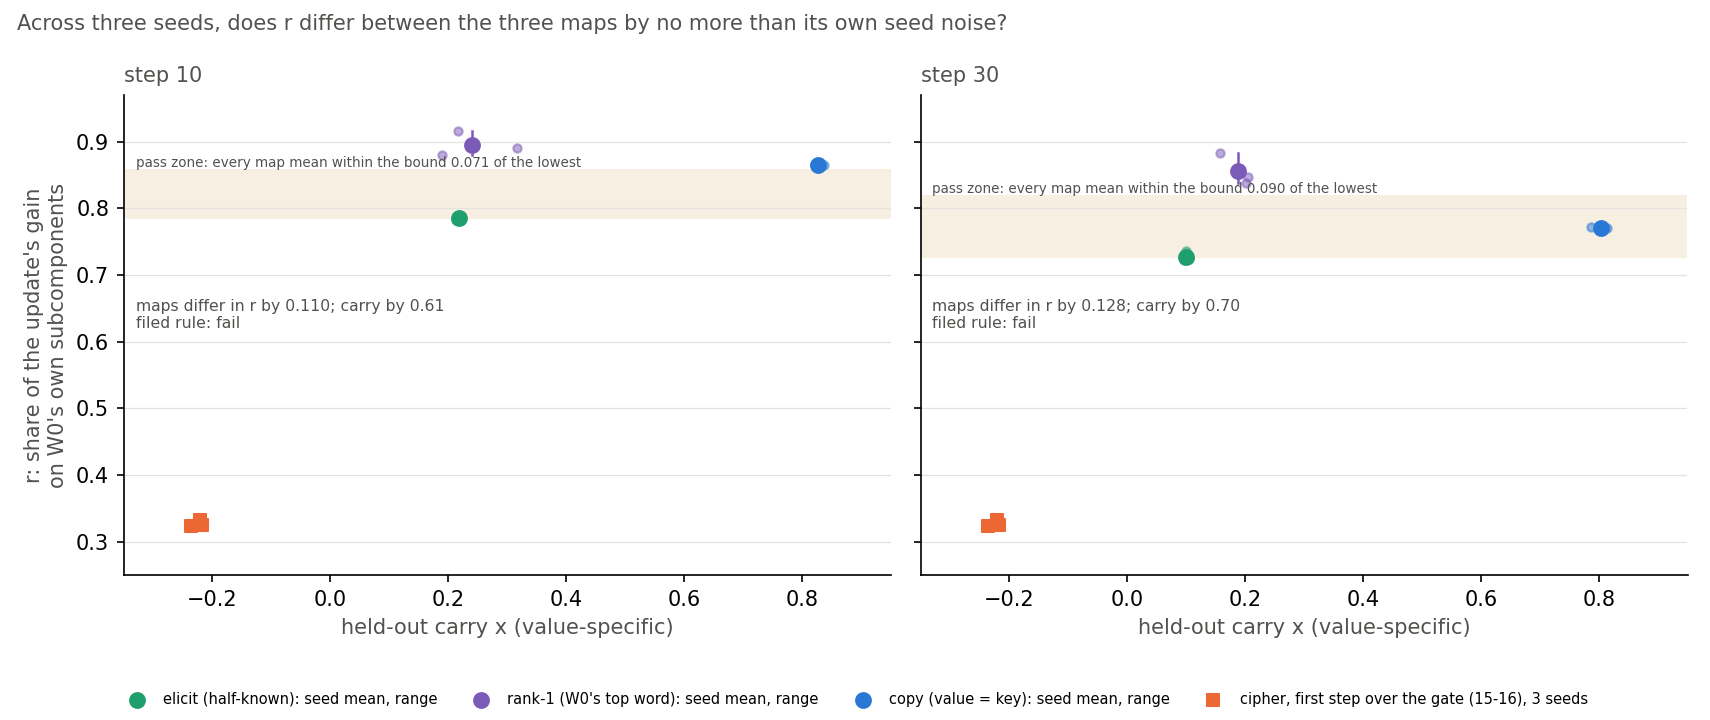

In [15]:
display(Image(filename=str(EXP / "figures" / "a4_within.png")))

In [16]:
rows = ["| step | carry spread | r spread | r bound | rule |", "|---|---|---|---|---|"]
for s in ("10", "30"):
    w = W4[s]["r"]
    rows.append(f"| {s} | {w['D_x']:.3f} | {w['D']:.3f} | {w['bound']:.3f} | {W4[s]['status']} |")
display(Markdown("\n".join(rows)))

| step | carry spread | r spread | r bound | rule |
|---|---|---|---|---|
| 10 | 0.609 | 0.110 | 0.071 | fail |
| 30 | 0.702 | 0.128 | 0.090 | fail |

**Reading it.** No: the filed rule fails at both steps, on r. Every seed's cipher read "below" first, and seed 0's
re-trained cipher reproduced Amendment 3 exactly. In the figure, the shaded band is the pass zone measured up from the
lowest map's mean r. The rank-1 map sits above it at both steps: the maps' mean r spans 0.110 against a bound of 0.071
at step 10, and 0.128 against 0.090 at step 30. The stand-in ratio's half passes, close to its bound. So the claim that r
reads the same across these maps is not supported as filed.

Unscored, the differences do not follow carry at step 10. Rank-1 has the highest r while carrying about a quarter;
copy carries over four fifths at a lower r. The rank correlation of r with carry over the nine reads is 0.02 at step 10
and 0.42 at step 30, with little power. All three maps stay far above the cipher. The copy map reads "reuses" on every
seed, so the held-out label's positive control now holds on three seeds.

### Same words, no link to the model's guess per key: does r read like the cipher?

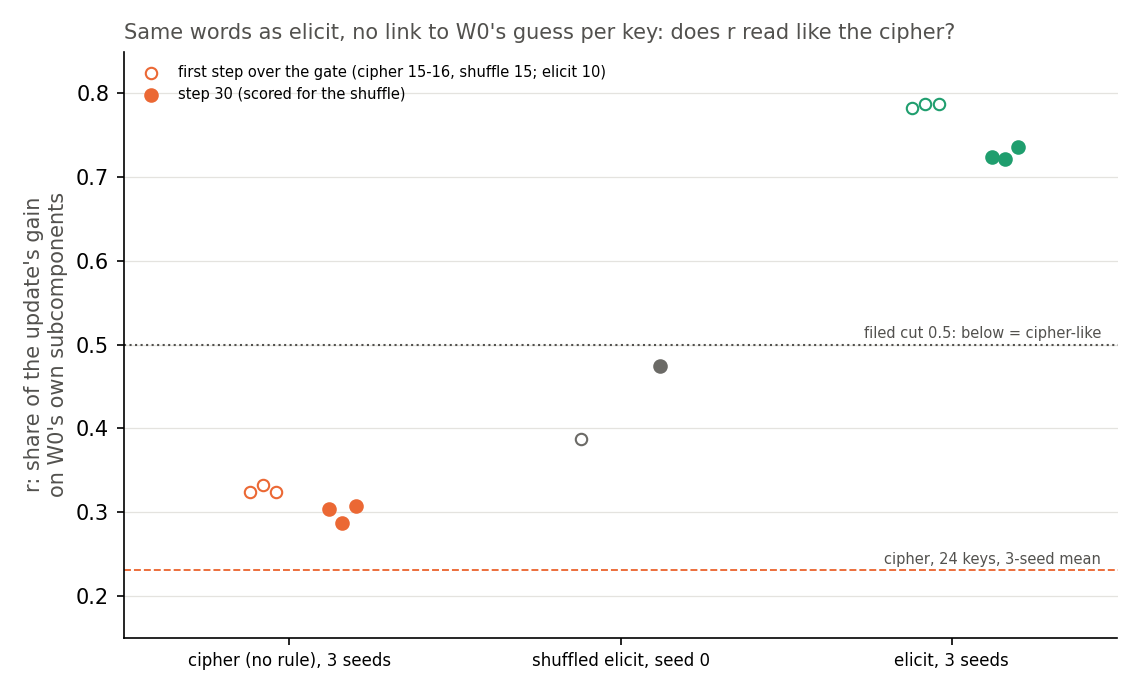

In [17]:
display(Image(filename=str(EXP / "figures" / "a4_shuffle.png")))

**Reading it.** Yes as filed, but near the cut. At step 30 the shuffled map's r is 0.475, under 0.5, so it reads
"cipher-like". It sits between the cipher's 0.29 to 0.31 and elicit's 0.72 to 0.74, closer to the cut than to either.
At its first step over the gate its r was 0.39, beside the cipher's 0.32 to 0.33. It was trained about as far as the
others: its trained-key gain at step 30 was 17.5, against 16 to 19 for the cipher and elicit. Scored on seed 0; Amendment 5 below reads the same on two more seeds. A new
circuit built from old subcomponents would still read as old in r: the granularity limit holds here as everywhere.

### Amendment 5: the shuffled map on two more seeds

Amendment 4's scored shuffle read is one seed, 0.025 under its cut. A third $0 job trained seeds 1 and 2 of the same
shuffled map, read at step 30 and at the first step over the gate. A write-up rule was fixed before the run, not a
scored prediction. If both new seeds read over 0.55, the claim changes to "targets the model can produce somewhere". If
any seed reads 0.5 or over, the shuffle is "at the midpoint". Otherwise "mostly the key-conditional guess, partly the
token kind" stands. The job added no new measurement code, so no separate code review was run.

| shuffled map | first over the gate: step, r | r at step 30 | ratio at step 30 |
|---|---|---|---|
| seed 0, Amendment 4 | 15, 0.388 | 0.475 | 0.650 |
| seed 1 | 15, 0.392 | 0.485 | 0.659 |
| seed 2 | 15, 0.360 | 0.471 | 0.643 |

**Reading it.** The sentence stands on three seeds: r mostly reads whether a target is the model's own guess for that
key, partly the kind of word. All three seeds read just under the cut, mean 0.477, between the cipher's 0.30 and
elicit's 0.73. As in Amendment 4, a new circuit built from old subcomponents would still read as old.

## Amendment 6: does r read only W₀'s prior of the trained value?

In every map so far, two things moved together: whether the target is W₀'s own guess for that key, and W₀'s prior of
the target. The prior is W₀'s geometric-mean probability of the trained value after the marker and its key; it reads
1.4e-6 for the cipher and 5.9e-5 for copy. Since "own guess" is a cut on the prior, a review asked whether r reads
anything the prior does not. A fourth $0 job trained two new maps on the same 96 trained and 32 held-out keys, three
seeds each:

- **A prior-matched cipher.** Each key gets a distinct word from the cipher's word pool with no link to the key, but a
  word is admitted only where W₀'s prior of it lies between 2e-5 and 2e-4. If r followed the prior smoothly, this map would
  read near copy; a cut on the prior between this map's and copy's would not be ruled out.
- **A first-letter rule.** Each key goes to one new word per first letter, 22 words, each at the cipher's prior. Unseen
  keys share letters with trained ones, so a fine-tune that learns the rule should carry. Its r is read only if it
  carries more than a null, which swaps each unseen key's target for another letter's word trained about as often.

Fable leaned 70% that the new cipher reads like the cipher, r under 0.5 on every seed; the plan's writer leaned 40%,
reasoning that the slope from the cipher to the shuffle, carried on, reaches about 0.6 at copy's prior. The writer
leaned 70% that the first-letter rule would not carry. Both controls passed first: a zero update read exactly 0, each
prior sat in its band, and E58's cipher seed 0 re-trained reproduced its r exactly.

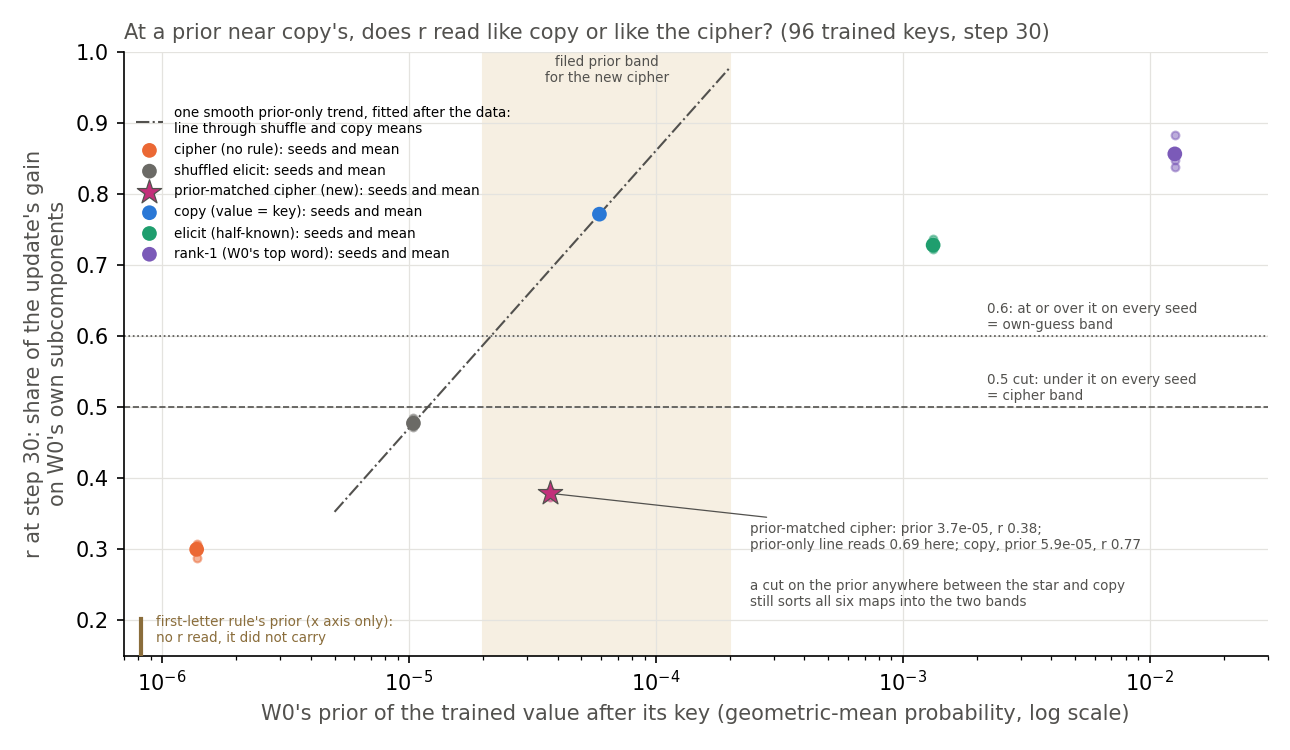

In [18]:
display(Image(filename=str(EXP / "figures" / "a6_prior.png")))

**Reading it.** Like the cipher. The star is the prior-matched cipher, r 0.37 to 0.38 at step 30 on its three seeds,
every one under 0.5. Its prior of 3.7e-5 is only a factor of about 1.6 below copy's, yet copy, the blue point, reads
0.77. The dash-dot line through the shuffle and copy is one smooth prior-only trend, fitted after the data;
it reads 0.69 at the star's prior. So on this one pair r is not a smooth function of the prior. Three caveats. A cut on
the prior anywhere between the star's and copy's still sorts all six maps into r's bands, so a step in the prior is not
excluded, and W₀'s own-guess ranking still predicts every band. The shuffle reads 0.48, above the star, at a lower
prior, so the word pool moves r as well. And copy differs from the new cipher in the own-guess link, in carry and in
trained gain, 25.4 to 25.7 against 19.0 to 20.1, so this does not say which difference r reads. The granularity limit stands beside it: a new
circuit of old subcomponents would still read as old.

| map | prior of trained values | r at step 30, seeds 0 / 1 / 2 | carry at step 30 |
|---|---|---|---|
| cipher | 1.4e-6 | 0.304 / 0.288 / 0.307 | −0.11 to −0.10 |
| shuffled elicit | 1.0e-5 | 0.475 / 0.485 / 0.471 | −0.05 to −0.03 |
| **prior-matched cipher** | **3.7e-5** | **0.373 / 0.381 / 0.382** | −0.007 to 0.005 |
| copy | 5.9e-5 | 0.771 / 0.772 / 0.771 | 0.79 to 0.81 |
| elicit | 1.3e-3 | 0.725 / 0.722 / 0.736 | 0.10 |
| rank-1 | 1.3e-2 | 0.847 / 0.883 / 0.838 | 0.16 to 0.20 |

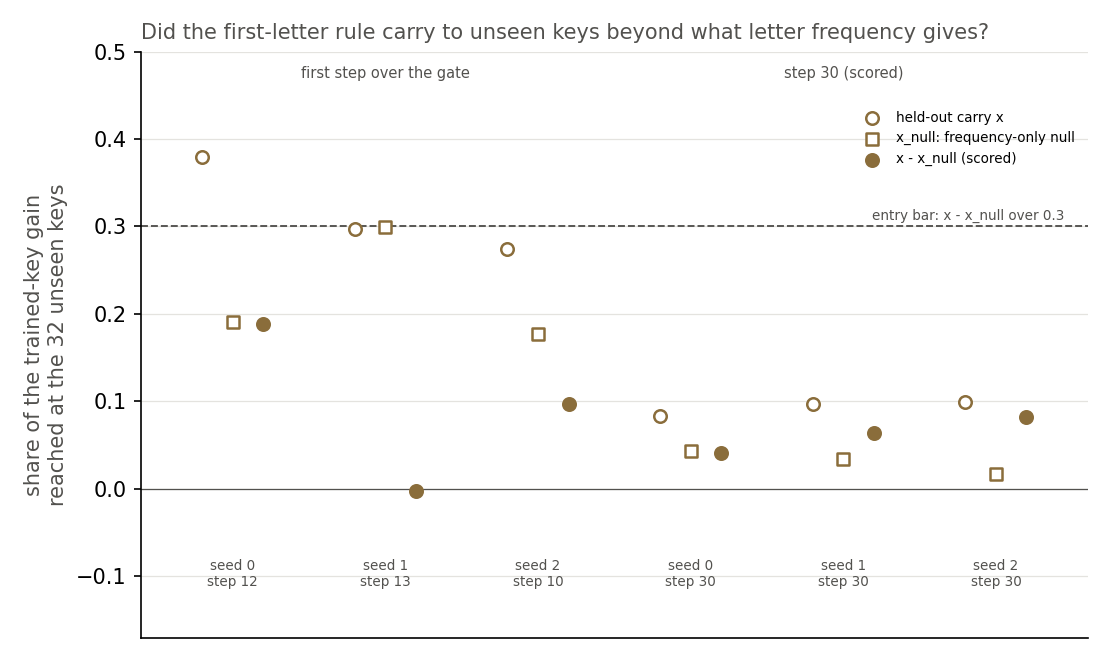

In [19]:
display(Image(filename=str(EXP / "figures" / "a6_first_letter.png")))

**Reading it.** No. At step 30 the carry beyond its frequency null was 0.04 to 0.08 on the three seeds, far under the
entry bar of 0.3, so the rule reads "no_carry" and its r was not read. At each run's first step over the gate the raw
carry was higher, 0.27 to 0.38, but the null took most of it. By step 30 the fine-tune behaves like a per-key lookup,
and its carry fell after the gate as the elicit map's did. So the cell "a new target that carries" stays empty on the
small model, and is the first thing to build on Qwen.

## Amendment 7: a new rule that carries, at a target W₀ does not guess

Every map so far that carried to unseen keys had W₀'s own guess as its target, and every map whose target W₀ does not
guess carried nothing. So "r reads the own-guess link" and "r reads carry" were never pulled apart, and Amendment 6's
first-letter rule, built to do it, did not carry. A fifth $0 job tried an easier rule on the same 96 trained and 32
held-out keys, three seeds per map:

- **The class map.** Each key's embedding row is placed on the two leading principal components of the trained keys'
  rows, and its class is the sign pair of its two scores: four classes. Each class goes to one word W₀ never gives after
  these keys, under 1e-5: " officers", " Plaintiff", " officer" and " electrode". The rule is a linear readout of the
  key's embedding, so a fine-tune can learn it, and its target is never W₀'s guess.
- **Its shuffled-class twin**, the control. The same four words and class sizes with the class labels shuffled over
  the keys, so there is no rule to carry.
- **The carry null.** Carry counts here only beyond $x_\text{null}$, which reads each class's word at the other classes'
  unseen keys with the same weights. A lean toward a word that is the same at every key then cancels exactly. A seed
  carries iff $x - x_\text{null} > 0.3$; the twin must stay under 0.15 on every seed.
- **A cipher at elicit's prior**, a rider to extend Amendment 6's prior test.

D is the class map's mean r minus the twin's: the two differ only in whether a rule exists. Fable leaned 60% that the
class map carries, the writer 50%; given carry, both leaned about even on the cipher band. The writer leaned 50% that
D would exceed its bound of 0.09, that is, that r sees carry. Every control passed first: zero updates read 0, both
maps' words sat under 1e-5, the class counts matched, and E58's cipher seed 0 reproduced its r exactly. The twin read
clean at step 30. The elicit-prior cipher could not be built, since 46 of the 128 keys had no admissible word, and was
skipped as filed.

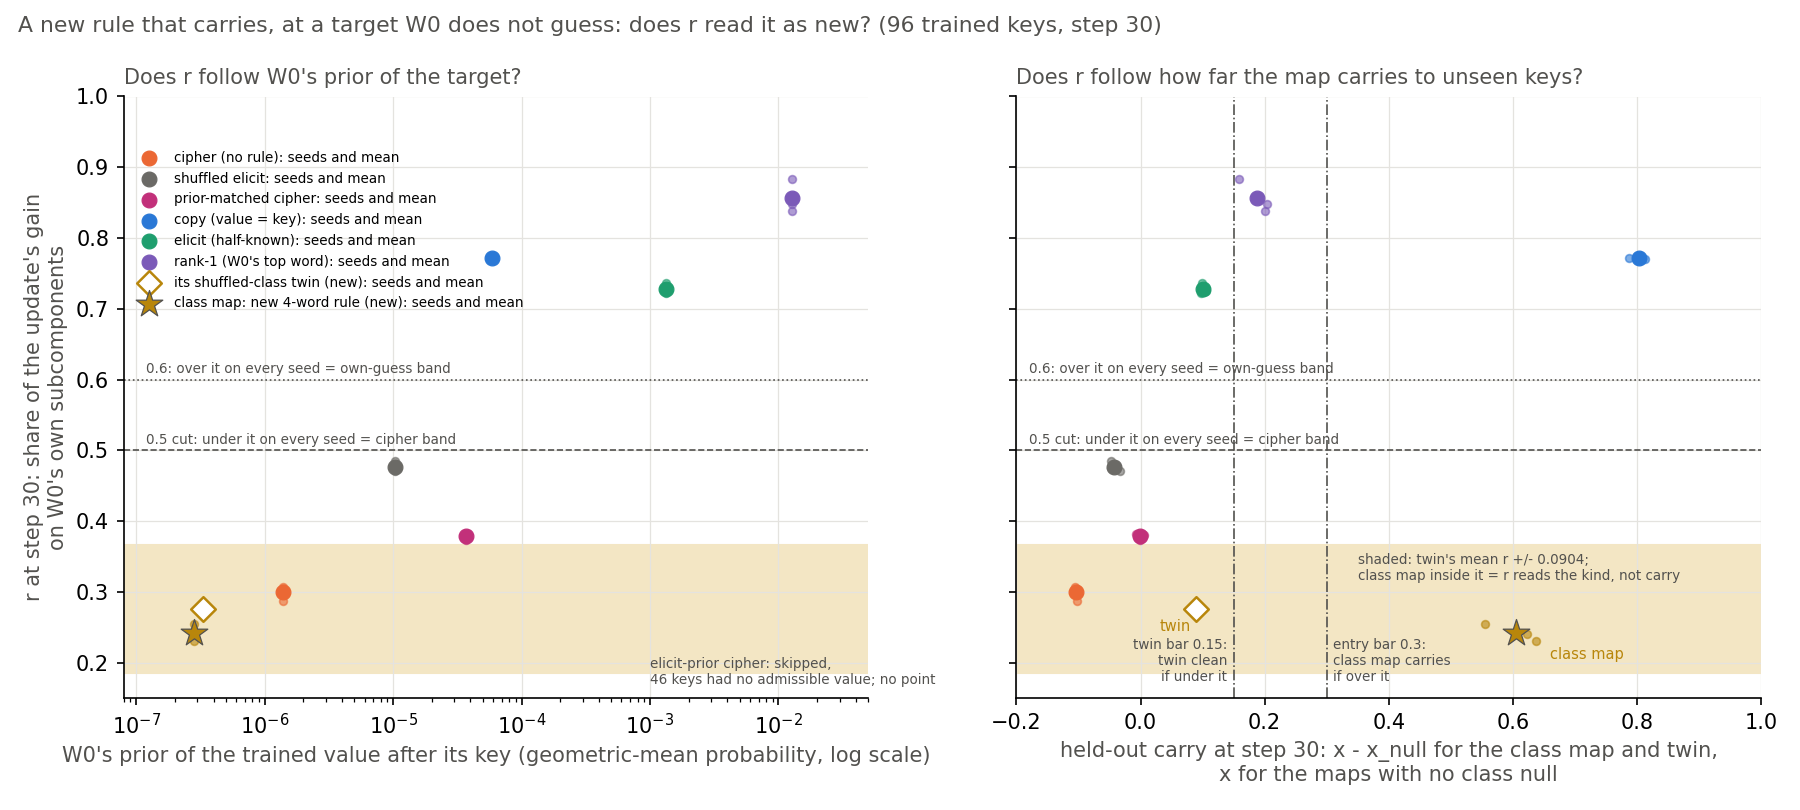

In [ ]:
display(Image(filename=str(EXP / "figures" / "a7_r.png")))

**Reading it.** Like a lookup. In the right panel the gold star, the class map, carries 0.55 to 0.64 beyond its null at
step 30, nearly as far as copy's 0.8. Yet its r is 0.23 to 0.25, in the cipher band. The hollow diamond, its twin with
no rule, carries under 0.1 and reads 0.27 to 0.28, so D is −0.03, inside the shaded band. Carry moved by about half the
trained gain between the two maps and r did not move with it. In the left panel every map with a low prior reads low,
and the class map and twin have the lowest priors of all. So r read a carrying rule built from directions W₀ already has
as new, like a lookup over the same words. The carry is not one class's lean: every class's word gains far more at its
own unseen keys than at the others', which the twin does not show.

Four caveats. The unseen keys fall unevenly over the classes, 18 of 32 in one class, though every class carries. The
class map's classes track embedding norm and token id a little, which the null does not fully cancel; a reported
reading that divides out each window's size of response still separates the class map from the twin. At the first step
over the gate, one twin seed carries 0.154, just over its bar, so there the filed reading is "control failed"; step 30
is the scored step, and the twin is clean there. The skipped rider leaves the prior's dose-response unread.

| map, step 30 | prior of trained values | r, seeds 0 / 1 / 2 | carry beyond null |
|---|---|---|---|
| **class map** | **2.8e-7** | **0.231 / 0.241 / 0.254** | **0.56 to 0.64** |
| shuffled-class twin | 3.3e-7 | 0.279 / 0.279 / 0.271 | 0.08 to 0.09 |
| cipher | 1.4e-6 | 0.304 / 0.288 / 0.307 | no null; carry −0.10 |
| copy | 5.9e-5 | 0.771 / 0.772 / 0.771 | no null; carry 0.79 to 0.81 |

**What it means.** r does not read carry: a rule that generalises and a lookup over the same new words read alike, while
copy, which carries as far, reads high. Across all eight maps r follows whether the trained answer is W₀'s own guess, and
the granularity limit did not make this rule read as old. What it cannot show is whether r reads the mechanism or only
the target: a new rule onto answers W₀ already gives, where the limit would bite, is untested.

## What we learned

This is the lead's reading, not a proof: no check here separates it from "the decomposition is wrong".

VPD's unit is the rank-one subcomponent, so a new lookup built from old subcomponents, switched on in a new pattern,
reads "elicited" to r and the stand-in ratio. Here the elicit values are words W₀ already says after these keys, so the
subcomponents that write them exist; the cipher's do not, and its readings are low. The held-out label asks a
different question: does a rule carry to unseen inputs? On a lookup over existing words those two answers can differ,
and they do here at 24 trained keys, on three seeds each way. Every claim holds only at the level of VPD's subcomponents.

Amendment 1 confirms the lookup: the update pushed the trained answers, not W₀'s own preferences. At 24 keys the label's
positive control failed, so E58's failed agreement test counts neither for nor against VPD.
Amendments 2 and 3 gave carry room to move. With 96 trained keys every map carried further, and the copy map cleared the
label's bar; Amendment 4 showed it on all three seeds, so the label has a positive control at 96 keys. The filed test of
whether r follows carry across key counts reads "untested", because the no-rule cipher's r itself rose by 0.14 with the
key count.
Amendment 4 replaced the one-seed level picture: over three seeds r differs between the three own-guess maps by more
than twice its seed noise at both read steps. Its order is not carry order: rank-1 has the highest r and carries about a
fifth, while copy carries over four fifths at lower r. The shuffled map, elicit's words with no link to the model's guess
per key, reads r 0.477 over three seeds with Amendment 5, under the cut but only 0.015 to 0.03 below it. So r agrees with
whether the target is W₀'s own guess for that key, which W₀'s prior already gives.

Amendment 6 asked whether r reads more than that prior. A no-rule lookup whose values W₀ rates only about 1.6 times
less likely than copy's read r 0.37 to 0.38, with the cipher, while copy reads 0.77. So on this one pair r is not a smooth
function of the prior, though a cut on the prior between the two maps still sorts every map. Copy also differs in the
own-guess link, carry and trained gain, so this does not say which difference r reads. The first-letter rule, built to be the first new target that carries, did not carry beyond
what letter frequency gives, so no map here has a target W₀ does not guess that still carries. A new circuit of old
subcomponents would read the same way. Ask #14 stays open.

Amendment 7 filled that cell for one rule. A four-word rule over the sign pair of each key's two leading embedding
directions carried 0.55 to 0.64 beyond its null, while its shuffled twin carried under 0.1. Both read r 0.23 to 0.28,
with the lookups, while copy reads 0.77. So r does not read carry; across all eight maps it follows whether the trained
answer is W₀'s own guess, which W₀'s prior already gives. The rule is built from directions W₀ has and still read as
new, so the granularity limit did not bite here; it stays untested where it would, a new rule onto answers W₀ already
gives.

## How compelling is the evidence

Three fine-tune seeds per map, one key split, one decomposition. The label's real unit is the 8 held-out keys, and it
holds when keys are resampled. The label is blind to a carry-over that raises every value alike. At 24 keys its positive control
failed: the copy map read "reuses" on one seed of three, and the rank-1 map was not testable on this split. A code
reviewer noted that the rank-1 values were picked on windows that include the scoring windows, which biases its carry
slightly toward "new" (reasoned, not measured). The readings reproduced E54 to four decimals before any fine-tune.

Amendments 2 and 3 rest on one seed and one key split, and two "flat" calls sit within 0.01 of their tolerance. The
drift guard compares a 96-key cipher that had barely learned its values with 24-key ciphers half way there, so it
cannot say what moved r.

Amendment 4 has three seeds but one key split and one decomposition; its rule's bound is wide, and r still exceeded it.
The shuffled map has three seeds with Amendment 5, 0.015 to 0.03 under its cut.

Amendment 6 tests one prior level with one word pool, on three seeds whose r spans 0.009. The shuffle reads 0.10 above
the prior-matched cipher at a lower prior, so the word pool moves r as well.

Amendment 7 is one rule over one feature, three seeds and one key split, with its unseen keys spread 4, 18, 9 and 1 over
the classes. Its twin carries 0.154 on one seed at its gate step and is clean at step 30, the scored step. The rider at
elicit's prior was skipped.

## Surprises

- **Amendment 7: the class map carried 0.55 to 0.64 beyond its null**, where the writer leaned 50% on any carry, since
  each class direction holds under 3% of the embedding variance. At its gate step E58's label read it "reuses" on all
  three seeds.
- Amendment 7: the class map's r, 0.23 to 0.25, sits under the cipher's 0.29 to 0.31. The twin cleared the gate at
  steps 16 to 19, against the filed 10 to 13. The elicit-prior cipher could not be built.

- **Amendment 6: the prior-matched cipher read 0.37 to 0.38**, under the shuffle's 0.48 though its prior is 3.6 times
  higher. Fable leaned this way at about 70%; the plan's writer leaned 40%, expecting about 0.6, a miss of about 0.2.
- Amendment 6: the prior-matched cipher was already over the gate at step 10, the first read step, against the filed
  steps 12 to 16, so its true first step over the gate is unknown.
- Amendment 6: the first-letter rule's carry was 0.27 to 0.38 at its gate step and fell to 0.08 to 0.10 by step 30.

- **Amendment 4: the within-key-count rule failed at both steps.** Fable filed pass at about 70%, the plan's writer
  about 30%. r's spread across maps, 0.11 and 0.13, exceeded twice its seed noise; the ratio passed, near its bound.
- Amendment 4: the shuffled map read r 0.475, just under the cut of 0.5.
- **Something unexpected happened that stopped Amendment 2.** We filed the elicit map at 96 trained keys as a no-rule
  control, carry within ±0.05 at about 70%. It carried 0.21, on 28 of 32 unseen keys. Fable's reasoned cause, a rule
  that 96 keys make learnable, was neither confirmed nor refuted by Amendment 3's checks.
- Amendment 2: three set-up expectations missed. The rank-1 map had 10 held-out keys of its own, not 1 to 6. The
  elicit map's trained-key gain was 9.34, under the filed 10 to 19, and its trained-key probability at step 10 was
  already 0.60, where the plan expected under 0.5.
- Amendment 3: the drift guard fired, filed at about 10%: the cipher's r rose from 0.23 to 0.37 with the key count.
- Amendment 3: the shuffled elicit map fell under the gate, so its check could not be read. The elicit update lowered
  the copy key itself at unseen keys by 1.0 log-odds, outside the filed ±0.5.
- **A filed prediction failed against a confident lean.** We put the copy map reading "reuses" on two of three seeds at
  about 75%; it did on one. It was filed as always testable, so it is a fail.
- The rank-1 map had a single held-out key with a value of its own; the stand-in ratio read above 1 on both controls.
- A filed prediction failed: the decomposition's labels disagree with the behavioural label on every elicit state. It
  was filed at about even odds, so this is a failure as filed, not a reversal of a confident lean.
- Steering's share on the elicit map rose to about 0.5 with 24 keys, from about 0.39 with all 32. We assert no cause.
- At unseen keys the cipher pushes its trained values up by about 5.6 log-odds, three times the elicit map's push.

## What next

Amendment 6's filed step, E45 Amendment 2's Qwen run going ahead as filed, is stale: E57's first control read r 0.99 on
random weight changes, so Job 2's ordering is open until a Qwen reading fails a random change. Fable's later advice puts
a new target that carries on the 67M first, with few classes of many keys each
(`reports/plans/2026-10-30_advice_regating-carry-cell-FABLE.md`).

After Amendment 3 the verdict was "untested". Amendment 4 then added seeds 1 and 2 and read the shuffled map over the
gate; its results are above. What follows is the lead's; the step the data still point to is the drift guard re-read at
matched training, which says whether r's level depends on the key count.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| P0 | the elicit label, a lean toward "reuses" | new ×3 | new; lean missed |
| P1 | every cipher reads "new" | new ×3 | pass |
| P2 | r's and the ratio's labels equal the behavioural label | reuses ×3 vs new ×3 | **fail**, both |
| P3 | the decomposition agrees with the label more often than steering | r 3, ratio 3, S 5 of 6 | "steering_better" as scored; not a finding, S on its cut |
| P4 | r and the ratio separate elicit from cipher, as E54 | gaps 0.54, 0.62; ranges 0.03 | pass, both |
| A1 | at unseen keys every elicit update is a lookup | gap 2.1-2.2 vs 3 sd 0.23 | pass |
| C1 | the rank-1 map reads "reuses" on 2 of 3 seeds | 1 novel key of 3 needed; neither ×3 | not testable |
| C2 | the copy map reads "reuses" on 2 of 3 seeds | neither, reuses, neither | **fail** |
| verdict | the label has a positive control | C1 not testable, C2 fail | none |
| C3 | r and the ratio agree with each earned label | copy seed 1 only | pass, both, n = 1 |
| A2 E | the elicit map at 96 trained keys does not carry | x 0.213, 3 sd 0.041 | **fail**; job stopped |
| A3 control | the cipher at 96 trained keys does not carry | step 16: x −0.236 | below; continue |
| A3 R | the rank-1 map at 96 keys | x 0.317, novel keys 0.095 | between |
| A3 C | the copy map at 96 keys carries 0.6 or more | x 0.823 | pass |
| A3 B | r and the ratio move with carry, each map against 24 keys | every map flat; cipher r drift 0.138 > 0.05 | untested_drift |
| A3 verdict | reading A holds, or r tracks carry | B untested_drift | **untested** |
| A3 checks | carry over training; shuffled map; cross-reads; rank correlation | falling; too small; copy key −1.0; 0.01 and 0.19 | reported |
| A4 control | the cipher does not carry, seeds 0-2 | steps 16, 16, 15: x −0.24 to −0.22 | below ×3 |
| A4 W10, W30 | r and the ratio differ across maps by no more than seed noise | r spread 0.110 vs bound 0.071; 0.128 vs 0.090 | **fail** both (Fable ~70% pass, writer ~30%) |
| A4 shuffle | the shuffled map's r reads like the cipher, cut 0.5 | r 0.475 at step 30 | cipher_like |
| A5 shuffle, seeds 1-2 | reported write-up rule | r 0.485, 0.471; mean of three 0.477 | mostly key-conditional |
| A6 controls | zero update reads 0; priors in band; cipher seed 0 reproduces r 0.32413 | 0; 3.7e-5 and 8.2e-7; identical | pass |
| A6 PM | the prior-matched cipher's r at step 30 reads in the cipher band | r 0.373, 0.381, 0.382 | **cipher_band** (Fable ~70%, writer ~40%) |
| A6 FL | the first-letter rule carries beyond its null, then its r | difference 0.040, 0.063, 0.082 vs bar 0.3 | **no_carry** (writer ~70%) |
| A7 controls | zero update and nulls read 0; words under 1e-5; filed counts; cipher seed 0 reproduces r | 0; 2.8e-7, 3.3e-7; as filed; identical | pass |
| A7 T | the shuffled-class twin is clean at step 30, under 0.15 | 0.093, 0.083, 0.091 | **clean** (writer ~75%) |
| A7 CL | the class map carries beyond 0.3, then its r band | carry 0.637, 0.623, 0.555; r 0.231, 0.241, 0.254 | **cipher_band** (Fable ~60% carry, ~50% band) |
| A7 D | class-map r minus twin r, bound ±0.0904 | −0.034 | **kind_only** (writer ~40%) |
| A7 EP | the elicit-prior cipher's r band | 46 keys with no admissible word | **skipped** |
| A7 at gate step | the same, reported | twin seed 0 at 0.154 | control_failed, D not read |

## Departures from the literature

- The bar is the reuse line's Stage B rule, from Jain et al.'s Definition 2 with the user's bounded g. Stage B reads the
  share an interchange patch carries; here it is read on behaviour only, with no patch.
- The gain is value-specific, the map's other values' mean gain subtracted, filed before any fine-tune.
- The bootstrap resamples windows, which share keys, where Stage B resamples independent texts; a key-level bootstrap is
  reported and changes no label.
- The 0.5 cut on the stand-in ratio copies E12's rule for r; the ratio has no ceiling at 1, so the cut is a convention.
- The gate on the trained-key gain was lowered from 8 to 5.148 before any fine-tune, keeping Fable's fraction of E54's
  gain; every elicit state cleared it by more than three times.
- Amendment 1: the rank-1 values are W₀'s top token over E54's training windows of each key. Those include the scoring
  windows, an in-sample choice for W₀ only.
- Amendment 1: ranks are over the full vocabulary, not word-like tokens only. The gate is E58's, not set from W₀'s
  rank-1 probability. The copy map always ran, and a 3-key guard was added to the rank-1 map.
- Amendments 2 and 3: every map read at one common step; the control's bar stops only above +0.05; the ratio's
  tolerance is 0.1, not Fable's 0.05, from its measured seed range; the rank-1 bars also need the novel keys to agree.
- Amendment 3: the cipher read at the first step over the gate when under it at the common step; the shuffle is a
  cycle, not any permutation; the shuffle check is reported, not a stop; every map compared with itself, with a drift
  guard on the cipher's r.
- Amendment 4: definitions Fable left open, filed before the run: the seed spread is the largest within-map range of
  r, D uses seed means, and the ratio's 0.2 is an absolute bound; the shuffle runs on seed 0 only.
- Amendment 6: Fable asked for values at copy's prior from a band of 2e-5 to 2e-4; the realised prior is 3.7e-5, a
  factor of about 1.6 under copy's. One word per first letter present, 22, not Fable's 26; the entry bar is on carry
  minus its frequency null, after the code review; the capitalised-key rule and novelty column were not run.

## Not run

A rank-1 map on a split with 3 or more held-out keys of its own, or with values picked apart from the scoring windows.
The control maps at later steps or under another recipe. The novelty column on Γ's CI patterns. The interchange patch.
More key splits, seeds or decomposition seeds; the cipher at its own step; Qwen. After Amendment 3: more seeds or another key split
at 96 keys; the drift guard at matched training; the shuffled map over the gate; r at steps 100 and 300; a label against
a random token pool. After Amendment 4: the shuffle on more seeds;
the rule at matched training; another key split or decomposition seed. After Amendment 6: the capitalised-key rule;
the novelty column; the prior-matched cipher at other priors or from elicit's words; the first-letter rule at more keys
or on Qwen; per-key prior against per-key r; the independent check of the updated synthesis. After Amendment 7: the elicit-prior cipher, skipped; a new rule onto answers W₀ already gives; r on the class
map at step 100; a second rule, key split or decomposition seed; the class rule on Qwen; the independent check.

## Provenance

Job 46266, MATS `debug`, one L40, $0, about 3 minutes; code `b11a921`, results commit `16f43d6`. Stopped stage-0 job
46259, results commit `080b1f2`. Amendment 1: job 46332, MATS `debug`, one L40, $0, about 3 minutes; code `0714b79`,
results commit `c1b4ef9`. Amendment 2: job 46383, stopped at its control, code `aff6e79`,
results commit `fe29938`. Amendment 3: job 46398, MATS `debug`, one L40, $0, about 5 minutes; code `a37d68d`,
results commit `568bb41`; figures from `experiments/open_pair/plot_amend3.py`. Amendment 4: job 46426, MATS `debug`, one L40, $0, about
11 minutes; code `e87d3a0`, results commit `4c9c983`; figures from `experiments/open_pair/plot_amend4.py`. Amendment 5: job 46450, $0. Amendment 6: job 46489, MATS `debug`,
one L40, $0, about 6 minutes; code `5643589`, results commit `21685e0`; figures from
`experiments/open_pair/plot_amend6.py`. Amendment 7: job 46673, MATS `debug`, one L40, $0, about 11 minutes; code `9c47c08`, results
commit `bf7087f`; figure from `experiments/open_pair/plot_amend7.py`. Weight changes and logs in `~/commute-data/results-large/open_pair/`.